# 03 — Classification ascendante hiérarchique (CAH)

Objectif : construire une segmentation sur les coordonnées factorielles de l'**ACM final (itération 3)**, étudier le nombre d'axes (4, puis éventuellement 5 ou 6), examiner les hauteurs de Ward et comparer les partitions en **k − 1, k et k + 1** groupes.

**Attention aux ressources :** une CAH exacte sur environ 68 218 individus peut demander plusieurs dizaines de Gio de RAM. Le premier lancement est volontairement un **essai technique sur 3 000 individus**. Il ne représente pas la partition définitive de la totalité de l'échantillon ACM. La CAH complète doit être activée séparément et seulement après vérification des ressources.

In [48]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display

RACINE = Path.cwd().resolve()
if RACINE.name == "notebooks":
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from src.classification_hierarchique import (
    charger_coordonnees_et_identifiants, choisir_axes,
    selectionner_sous_echantillon, estimer_memoire_distances,
    effectuer_cah, obtenir_partition, tailles_groupes,
    hauteurs_fusions,
)
from src.evaluation_clusters import (
    calculer_silhouette_echantillon, comparer_partitions,
    tableau_croise_partitions,
)
from src.visualisation_cah import afficher_dendrogramme, afficher_hauteurs

## 1. Charger les résultats de l’ACM définitif

Les lignes des coordonnées et des identifiants doivent correspondre exactement. L'identifiant technique `indice_ligne_source`, s'il est utilisé, n'est **pas** un identifiant client pérenne.

In [49]:
coordonnees_factorielles, identifiants, metadonnees_acm = (
    charger_coordonnees_et_identifiants(RACINE)
)
print(f"Coordonnées factorielles disponibles : {coordonnees_factorielles.shape}")
print(f"Colonne d'identification : {metadonnees_acm.get('colonne_identifiant')}")
display(identifiants.head())

Coordonnées factorielles disponibles : (68218, 32)
Colonne d'identification : id_anonyme


,position_echantillon,id_anonyme
0,0,732b17b69563608c305596b612987b34aa6cb78b95aa86...
1,1,73f52ec545df5ce3b1a3fd90abdd76ec5bd4137fe14bdd...
2,2,9e40eee05b42e2d8c99ff8a972ff66f47db2614f7fc966...
3,3,0b8146f0a00c5cf4c3962373218cb5309a8f64b09ac645...
4,4,0c049beaeada4fc987a933703e1a87e4d290fbf81d9343...


## 2. Paramètres de l’expérience

- **4 axes** constituent l'hypothèse de départ ; une étude de sensibilité à 5 et 6 axes peut suivre.
- **3 000 individus** sont utilisés pour tester le fonctionnement sans consommer toute la mémoire.
- Pour traiter **tous les individus de l'ACM (20 % de la base)**, passer `EXECUTION_COMPLETE` à `True` uniquement après vérification du budget mémoire.
- `BUDGET_MEMOIRE_GIO` est un plafond de prudence configuré par l'utilisateur ; ce n'est pas une mesure de la RAM disponible.

In [50]:
NOMBRE_AXES_CAH = 4
EXECUTION_COMPLETE = False
TAILLE_ESSAI = 20000
GRAINE = 42
BUDGET_MEMOIRE_GIO = 8.0
CONFIRMER_DEPASSEMENT = False
MOTEUR = "scipy"  # "scipy" ; ou "fastcluster" si installé

coordonnees_selectionnees = choisir_axes(coordonnees_factorielles, NOMBRE_AXES_CAH)
positions = selectionner_sous_echantillon(
    len(coordonnees_selectionnees),
    taille=None if EXECUTION_COMPLETE else TAILLE_ESSAI,
    graine=GRAINE,
)
coordonnees_cah = coordonnees_selectionnees.iloc[positions].reset_index(drop=True)
identifiants_cah = identifiants.iloc[positions].reset_index(drop=True)
estimation = estimer_memoire_distances(len(coordonnees_cah))
estimation_complete = estimer_memoire_distances(len(coordonnees_selectionnees))
print(f"Mode : {'complet' if EXECUTION_COMPLETE else 'essai technique'}")
print(f"Individus sélectionnés : {len(coordonnees_cah)} / {len(coordonnees_factorielles)}")
print(f"Nombre d'axes retenus : {NOMBRE_AXES_CAH}")
print(f"Mémoire minimale distances, essai : {estimation['memoire_minimale_gio']:.2f} Gio")
print(f"Mémoire prudente, CAH complète : {estimation_complete['memoire_prudente_gio']:.1f} Gio")

Mode : essai technique
Individus sélectionnés : 20000 / 68218
Nombre d'axes retenus : 4
Mémoire minimale distances, essai : 1.49 Gio
Mémoire prudente, CAH complète : 43.3 Gio


## 3. Construction de la CAH par Ward

La hiérarchie est construite sur des coordonnées euclidiennes (sans standardisation supplémentaire, afin de conserver la pondération factorielle de l'ACM). L'estimation mémoire est une approximation et ne remplace pas la surveillance des ressources.

Fusions calculées : 19999


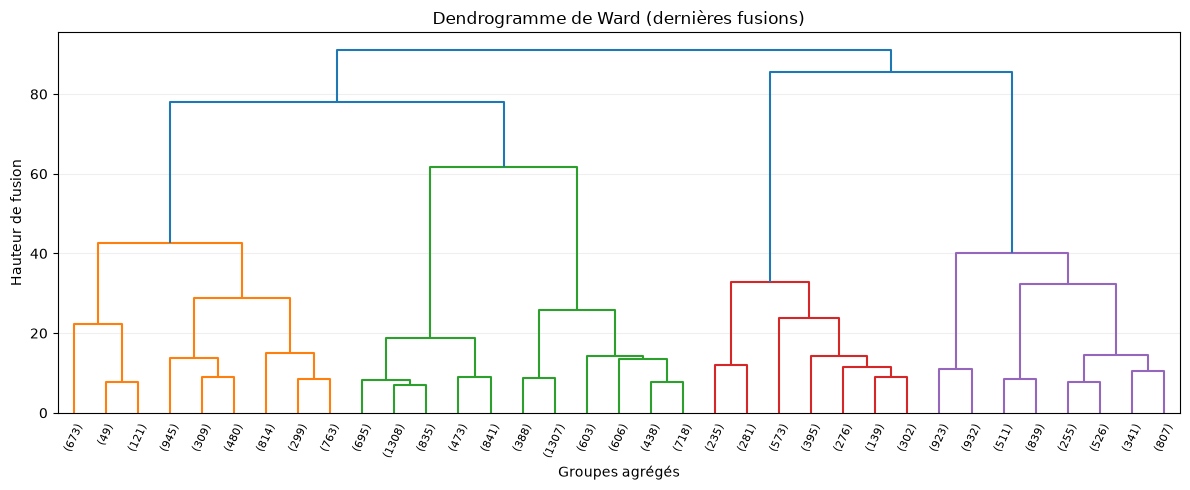

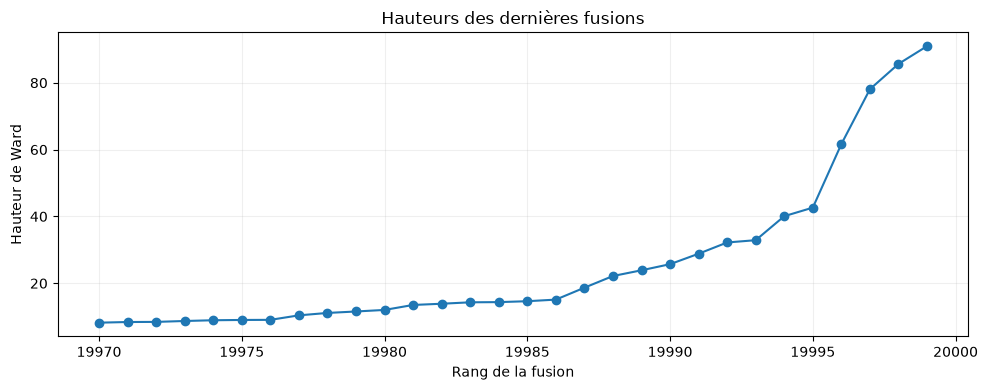

,Rang_fusion,Hauteur,Saut_hauteur
0,19985,14.632573,0.271109
1,19986,15.111659,0.479086
2,19987,18.679072,3.567413
3,19988,22.172921,3.493849
4,19989,23.888175,1.715254
5,19990,25.713398,1.825223
6,19991,28.843123,3.129726
7,19992,32.210374,3.367251
8,19993,32.892689,0.682315
9,19994,40.076468,7.183779


In [51]:
hierarchie = effectuer_cah(
    coordonnees_cah,
    budget_memoire_gio=BUDGET_MEMOIRE_GIO,
    confirmation_depassement=CONFIRMER_DEPASSEMENT,
    moteur=MOTEUR,
)
print(f"Fusions calculées : {len(hierarchie)}")
afficher_dendrogramme(hierarchie, derniere_fusions=35)
afficher_hauteurs(hierarchie, derniere_fusions=30)
display(hauteurs_fusions(hierarchie, nombre_dernieres=15))

### Évolution des hauteurs des dernières fusions

Ce graphique est construit directement à partir de `hierarchie`. La ligne pointillée illustre une coupure à cinq groupes, sans imposer ce choix comme partition définitive.


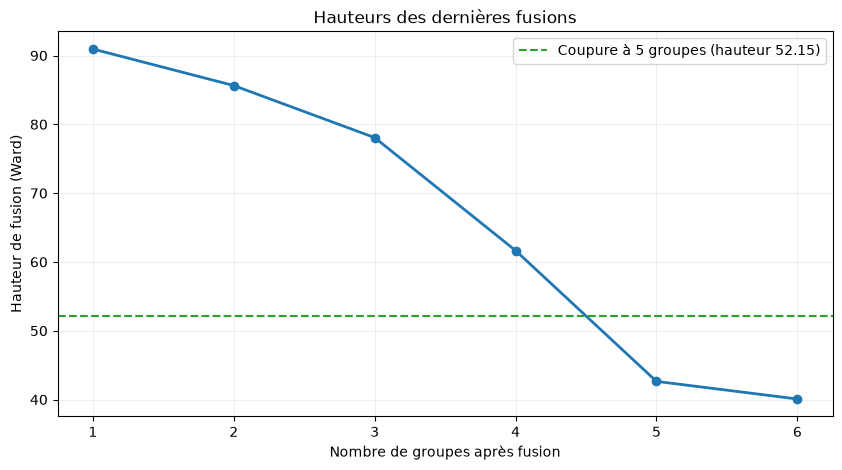

In [52]:
# Visualisation des hauteurs des dernières fusions selon le nombre de groupes restant
import matplotlib.pyplot as plt

nombre_dernières_fusions = 6
hauteurs_dernieres = hierarchie[-nombre_dernières_fusions:, 2]
nombres_groupes_restants = np.arange(nombre_dernières_fusions, 0, -1)

fig, axe = plt.subplots(figsize=(10, 5))
axe.plot(
    nombres_groupes_restants,
    hauteurs_dernieres,
    marker="o",
    linewidth=2,
)

# La coupure entre les fusions à 5 et 4 groupes produit une partition en 5 groupes.
if len(hauteurs_dernieres) >= 3:
    hauteur_coupure = (hierarchie[-5, 2] + hierarchie[-4, 2]) / 2
    axe.axhline(
        hauteur_coupure,
        color="tab:green",
        linestyle="--",
        label=f"Coupure à 5 groupes (hauteur {hauteur_coupure:.2f})",
    )

axe.set(
    xlabel="Nombre de groupes après fusion",
    ylabel="Hauteur de fusion (Ward)",
    title="Hauteurs des dernières fusions",
)
axe.set_xticks(nombres_groupes_restants)
axe.grid(alpha=0.2)
axe.legend()
plt.show()


## 4. Choisir k et confronter k − 1 / k / k + 1

Examiner les sauts des dernières fusions pour proposer `K_CENTRAL`. Les résultats ci-dessous servent ensuite à discuter les tailles des groupes et leur intérêt métier. Les numéros des clusters ne correspondent pas à une hiérarchie commerciale.

In [53]:
K_CENTRAL = 5  # Hypothèse à ajuster après lecture du dendrogramme
if K_CENTRAL < 3:
    raise ValueError("Choisir un k central >= 3 pour comparer k - 1, k et k + 1.")

partitions = {}
bilans = []
for nombre_groupes in [K_CENTRAL - 1, K_CENTRAL, K_CENTRAL + 1]:
    etiquettes = obtenir_partition(hierarchie, nombre_groupes)
    partitions[nombre_groupes] = etiquettes
    bilan = tailles_groupes(etiquettes, f"k={nombre_groupes}")
    bilans.append(bilan)
    score = calculer_silhouette_echantillon(coordonnees_cah, etiquettes)
    print(f"k={nombre_groupes} — groupes obtenus : {len(np.unique(etiquettes))} "
          f"— silhouette exploratoire : {score:.3f}")

bilan_tailles = pd.concat(bilans, ignore_index=True)
display(bilan_tailles)
for nombre_groupes in [K_CENTRAL - 1, K_CENTRAL + 1]:
    print(f"Comparaison k={K_CENTRAL} / k={nombre_groupes}")
    display(tableau_croise_partitions(partitions[K_CENTRAL], partitions[nombre_groupes]))
    display(comparer_partitions(partitions[K_CENTRAL], partitions[nombre_groupes],
                               f"k={K_CENTRAL}", f"k={nombre_groupes}"))

k=4 — groupes obtenus : 4 — silhouette exploratoire : 0.350
k=5 — groupes obtenus : 5 — silhouette exploratoire : 0.336
k=6 — groupes obtenus : 6 — silhouette exploratoire : 0.354


,Scénario,Groupe,Effectif,Part (%)
0,k=4,1,5134,25.670
1,k=4,2,8212,41.060
2,k=4,3,2201,11.005
3,k=4,4,4453,22.265
4,k=5,1,5134,25.670
5,k=5,2,4152,20.760
6,k=5,3,2201,11.005
7,k=5,4,4060,20.300
8,k=5,5,4453,22.265
9,k=6,1,5134,25.670


Comparaison k=5 / k=4


Groupe comparé,1,2,3,4
Groupe référence,,,,
1,5134,0,0,0
2,0,4152,0,0
3,0,0,2201,0
4,0,4060,0,0
5,0,0,0,4453


,Référence,Comparaison,ARI
0,k=5,k=4,0.779641


Comparaison k=5 / k=6


Groupe comparé,1,2,3,4,5,6
Groupe référence,,,,,,
1,5134,0,0,0,0,0
2,0,4152,0,0,0,0
3,0,0,2201,0,0,0
4,0,0,0,4060,0,0
5,0,0,0,0,843,3610


,Référence,Comparaison,ARI
0,k=5,k=6,0.953203


### Répartition des individus entre les partitions

Les barres empilées représentent la part de chaque groupe dans les partitions comparées. Les couleurs ne servent pas à identifier les mêmes groupes d’une partition à l’autre.


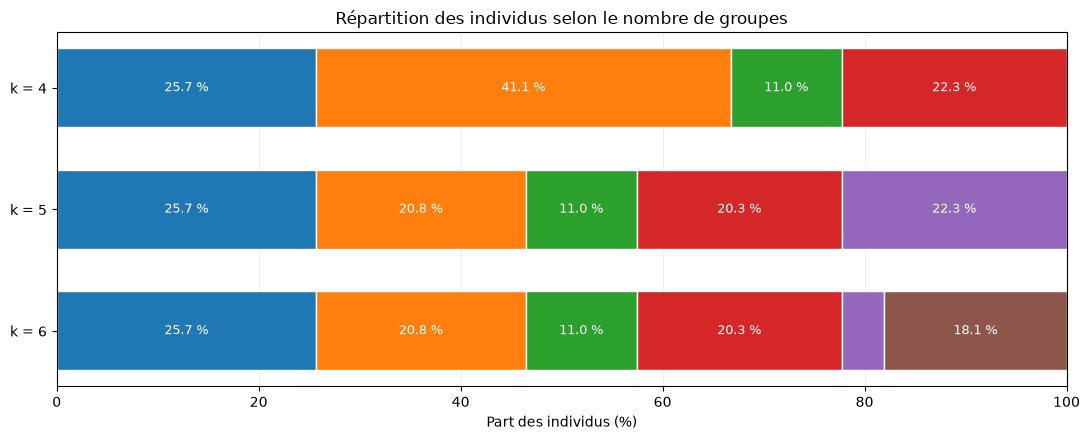

In [54]:
# Répartition des individus dans les partitions k - 1, k et k + 1
# Les couleurs distinguent les groupes au sein de chaque partition.
# Le même numéro de groupe ne désigne pas nécessairement les mêmes individus selon k.
fig, axe = plt.subplots(figsize=(11, 4.5))

nombres_groupes = sorted(partitions)
palette = plt.get_cmap("tab10")

for indice_ligne, nombre_groupes in enumerate(nombres_groupes):
    effectifs = pd.Series(partitions[nombre_groupes]).value_counts().sort_index()
    pourcentages = 100 * effectifs / effectifs.sum()
    debut = 0.0

    for indice_couleur, (groupe, pourcentage) in enumerate(pourcentages.items()):
        axe.barh(
            indice_ligne,
            pourcentage,
            left=debut,
            color=palette(indice_couleur),
            edgecolor="white",
            height=0.65,
        )
        if pourcentage >= 6:
            axe.text(
                debut + pourcentage / 2,
                indice_ligne,
                f"{pourcentage:.1f} %",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
            )
        debut += pourcentage

axe.set_yticks(range(len(nombres_groupes)), [f"k = {k}" for k in nombres_groupes])
axe.invert_yaxis()
axe.set_xlim(0, 100)
axe.set_xlabel("Part des individus (%)")
axe.set_title("Répartition des individus selon le nombre de groupes")
axe.grid(axis="x", alpha=0.2)
axe.set_axisbelow(True)
plt.tight_layout()
plt.show()


## 5. Exporter les partitions de l’expérience

Les fichiers de **l’essai technique** sont identifiés comme tels et **ne doivent pas être utilisés comme s'ils couvraient la totalité des 68 218 individus**. Le passage à l'échantillon complet produira des fichiers distincts. L'interprétation métier se fera dans `04_interpretation_clusters.ipynb`.

In [55]:
import json

repertoire_sortie = RACINE / "resultats" / "cah"
repertoire_sortie.mkdir(parents=True, exist_ok=True)
nom_mode = "complet" if EXECUTION_COMPLETE else "essai"
prefixe = f"{nom_mode}_{NOMBRE_AXES_CAH}axes"

partitions_export = identifiants_cah.copy()
for nombre_groupes, etiquettes in partitions.items():
    partitions_export[f"groupe_k{nombre_groupes}"] = etiquettes
partitions_export.to_csv(repertoire_sortie / f"partitions_{prefixe}.csv", index=False)
bilan_tailles.to_csv(repertoire_sortie / f"tailles_{prefixe}.csv", index=False)
hauteurs_fusions(hierarchie).to_csv(
    repertoire_sortie / f"hauteurs_{prefixe}.csv", index=False
)
parametres = {
    "mode": nom_mode,
    "nombre_individus": len(coordonnees_cah),
    "nombre_axes": NOMBRE_AXES_CAH,
    "k_central": K_CENTRAL,
    "valeurs_k": sorted(partitions),
    "graine": GRAINE,
    "methode": "ward",
    "distance": "euclidienne",
    "moteur": MOTEUR,
    "colonne_identifiant": metadonnees_acm.get("colonne_identifiant"),
    "source_acm": "itération 3",
}
with (repertoire_sortie / f"parametres_{prefixe}.json").open("w", encoding="utf-8") as fichier:
    json.dump(parametres, fichier, indent=2, ensure_ascii=False)
print(f"Résultats de l'expérience exportés dans : {repertoire_sortie}")

Résultats de l'expérience exportés dans : C:\Users\SebastianAraya\Documents\Documentos\LILLE\Master\3S\Clustering\clustering\resultats\cah


## 6. Sensibilité au nombre d'axes (4, 5, 6)

Comparer les partitions sur **les mêmes individus**. Cette étape est facultative et désactivée par défaut : elle recalcule une CAH par nombre d'axes et augmente donc le coût. Sur une CAH complète, la relancer uniquement si les ressources sont suffisantes. L'ARI est un indicateur d'accord entre partitions (1 = partitions identiques) ; il ne détermine pas seul le nombre d'axes à retenir.

In [56]:
# Analyse facultative : comparer les partitions pour 4, 5 et 6 axes
EXECUTER_SENSIBILITE = True
NOMBRES_AXES_COMPARAISON = [4, 5, 6]

if EXECUTER_SENSIBILITE:
    partitions_axes = {}
    resultats_axes = []
    for nombre_axes in NOMBRES_AXES_COMPARAISON:
        coordonnees_axes = choisir_axes(coordonnees_factorielles, nombre_axes)
        coordonnees_axes = coordonnees_axes.iloc[positions].reset_index(drop=True)
        hierarchie_axes = effectuer_cah(
            coordonnees_axes,
            budget_memoire_gio=BUDGET_MEMOIRE_GIO,
            confirmation_depassement=CONFIRMER_DEPASSEMENT,
            moteur=MOTEUR,
        )
        etiquettes_axes = obtenir_partition(hierarchie_axes, K_CENTRAL)
        partitions_axes[nombre_axes] = etiquettes_axes
        score = calculer_silhouette_echantillon(coordonnees_axes, etiquettes_axes)
        resultats_axes.append({"Nombre axes": nombre_axes, "k": K_CENTRAL,
                               "Silhouette exploratoire": score})
    display(pd.DataFrame(resultats_axes))
    for nombre_axes in NOMBRES_AXES_COMPARAISON:
        if nombre_axes != 4:
            display(comparer_partitions(partitions_axes[4], partitions_axes[nombre_axes],
                                       "4 axes", f"{nombre_axes} axes"))
else:
    print("Étude de sensibilité désactivée : activer EXECUTER_SENSIBILITE si nécessaire.")

,Nombre axes,k,Silhouette exploratoire
0,4,5,0.335515
1,5,5,0.276088
2,6,5,0.244313


,Référence,Comparaison,ARI
0,4 axes,5 axes,0.658603


,Référence,Comparaison,ARI
0,4 axes,6 axes,0.423409
